---

# Project Brief & Mid-Program Presentation: Air Quality & Health Impacts

**Event:** Data Science Bootcamp Mid-Program Presentations

**Date & Time:** Thursday, October 29 | 1:00 PM – 3:00 PM ET

**Presenter:** Derick (Assigned Focus: Air Quality & Health Impacts)

**Collaborator:** Lupita (Assigned Focus: NYC Climate Budgeting & Capital Investments), 
Guhfran Shuhood

**Project Repository:** `https://github.com/derickh-nyu/NYU-Tandon-Career-Hub-Fall-2026-Data-Science-Bootcamp-Group-Project.git`

---

## 1. Problem Statement & Project Design

### The Urban Challenge

Air pollution remains one of the most critical environmental health threats across New York City. While citywide pollution levels fluctuate, exposure is fundamentally unequal:

* **Disproportionate Exposure:** Pollutant emissions, ambient concentrations, and community vulnerability vary widely across neighborhoods.
* **Public Health Consequences:** Chronic and acute exposure to common pollutants directly correlates with elevated rates of respiratory illness (e.g., asthma hospitalizations), cardiovascular disease, cancers, and premature mortality.

### Objective & Core Questions

* How do ambient levels of key pollutants (**$\text{PM}_{2.5}$**, **$\text{NO}_2$**, and **$\text{O}_3$**) vary across NYC geographies and socioeconomically vulnerable populations?
* Can neighborhood-level air surveillance data predict disparities in respiratory and cardiovascular health outcomes?
* *Inter-project link:* How do these high-vulnerability air quality zones overlap with capital investments tracked in NYC Climate Budgeting (Lupita's focus)?

---

## 2. Dataset Overview & Scope

* **Primary Source:** NYC Department of Health and Mental Hygiene (DOHMH) via the [Environment & Health Data Portal](http://nyc.gov/health/environmentdata) and Real-Time Air Quality feeds.
* **Last Updated:** June 18, 2026
* **Granularity & Dimensions:**
* **Rows:** ~19,800 records
* **Columns:** 12 attributes
* **Unit of Analysis:** Individual Air Quality Measurement (indexed by `Unique ID`)
* **Temporal & Spatial Scope:** Multi-year surveillance across NYC boroughs, community districts, and UHF (United Hospital Fund) neighborhoods.



---

## 3. Initial Exploratory Data Analysis (EDA) Highlights

* **Key Target Pollutants:**
* **Fine Particulate Matter ($\text{PM}_{2.5}$):** Combustion-related particles penetrating deep into lung tissue.
* **Nitrogen Dioxide ($\text{NO}_2$):** Traffic- and heating-related emissions with sharp localized gradients.
* **Ozone ($\text{O}_3$):** Secondary photochemical pollutant peaking during warm summer months.


* **Preliminary Spatial & Vulnerability Trends:**
* Persistent spatial clustering of elevated $\text{NO}_2$ and $\text{PM}_{2.5}$ along heavy transportation corridors and historically industrial zones.
* Preliminary divergence in health burdens: Neighborhoods with similar ambient pollution levels often exhibit starkly different hospitalization rates, highlighting baseline health vulnerability and access disparities.



---

## 4. Statistical Modeling & Analysis Roadmap

* **Phase 1: Feature Engineering & Spatial Harmonization**
* Aggregate temporal sensor data into annual and seasonal neighborhood averages.
* Standardize geographic boundary mappings across DOHMH UHF neighborhoods and City Council/Community Districts.


* **Phase 2: Bivariate & Spatial Correlation Analysis**
* Compute correlation coefficients between multi-year pollutant concentrations and cardiovascular/asthma emergency department visits.


* **Phase 3: Multivariate Regression & Disparity Modeling**
* Fit multivariate linear/spatial regression models controlling for poverty rate, demographic vulnerability, and proximity to major traffic arteries.
* Identify outlier neighborhoods where health impacts exceed expected exposure baselines.



---

## 5. 5-Minute Presentation Slide Outline

| Slide | Topic | Key Talking Points | Time |
| --- | --- | --- | --- |
| **Slide 1** | **Title & Team** | Project title, team roles (Derick: Air Quality & Health; Lupita: Climate Budgeting). | 0:30 |
| **Slide 2** | **Problem Statement** | Air pollution as an environmental justice and health crisis; core research questions. | 1:00 |
| **Slide 3** | **Data Profile & Scope** | DOHMH dataset specs (19.8K rows, 12 columns, neighborhood surveillance metrics). | 0:45 |
| **Slide 4** | **Initial EDA & Visuals** | Spatial heatmaps of $\text{PM}_{2.5}$/$\text{NO}_2$ and vulnerability distributions. | 1:30 |
| **Slide 5** | **Modeling Plan & Synthesis** | Regression/correlation roadmap + connection to climate capital investments. | 0:45 |
| **Slide 6** | **Open Questions & Repo** | GitHub link, feedback requests for judges, transition to Q&A. | 0:30 |

---

## 6. Open Questions for Industry Judges (Q&A Focus)

1. **Spatial Aggregation:** Best practices for addressing the Modifiable Areal Unit Problem (MAUP) when aligning UHF neighborhood health data with capital project boundaries.
2. **Lagged Effects:** Recommendations on modeling temporal lag between air quality surveillance measurements and chronic health outcomes.
3. **Synthesis:** Most effective approaches to frame the joint narrative between health vulnerability metrics (Derick) and municipal capital allocations (Lupita).

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path.cwd() / "Air_Quality_and_Health_Impacts_20261028.csv"
df = pd.read_csv(csv_path)

display(df.head())

df.info()

,Unique ID,Indicator ID,Name,Measure,Measure Info,Geo Type Name,Geo Join ID,Geo Place Name,Time Period,Start_Date,Data Value,Message
0,979194,"1,427",Fine particles (PM 2.5),Winter mean,mcg/m3,UHF34,104,Pelham - Throgs Neck,2024,01/01/2024,5.834572,NaN
1,980097,"1,431",Nitrogen dioxide (NO2),Annual mean,ppb,UHF34,304,Upper West Side,2024,01/01/2024,18.288730,NaN
2,980098,"1,431",Nitrogen dioxide (NO2),Annual mean,ppb,UHF34,303,East Harlem,2024,01/01/2024,16.184849,NaN
3,980099,"1,431",Nitrogen dioxide (NO2),Annual mean,ppb,UHF34,302,Central Harlem - Morningside Heights,2024,01/01/2024,16.521823,NaN
4,980100,"1,431",Nitrogen dioxide (NO2),Annual mean,ppb,UHF34,301,Washington Heights,2024,01/01/2024,16.264552,NaN


<class 'pandas.DataFrame'>
RangeIndex: 19827 entries, 0 to 19826
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unique ID       19827 non-null  int64  
 1   Indicator ID    19827 non-null  str    
 2   Name            19827 non-null  str    
 3   Measure         19827 non-null  str    
 4   Measure Info    19827 non-null  str    
 5   Geo Type Name   19827 non-null  str    
 6   Geo Join ID     19827 non-null  int64  
 7   Geo Place Name  19827 non-null  str    
 8   Time Period     19827 non-null  str    
 9   Start_Date      19827 non-null  str    
 10  Data Value      19827 non-null  float64
 11  Message         0 non-null      float64
dtypes: float64(2), int64(2), str(8)
memory usage: 1.8 MB


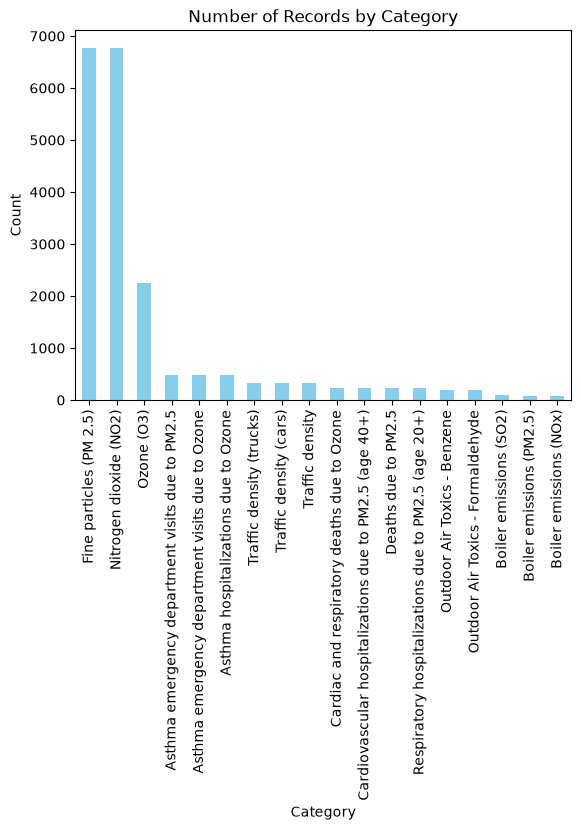

In [6]:

# 1. Count the occurrences and plot as a bar chart
df['Name'].value_counts().plot(kind='bar', color='skyblue')

# 2. Customize the chart
plt.title('Number of Records by Category')
plt.xlabel('Category')
plt.ylabel('Count')

# 3. Display the chart
plt.show()

In [7]:
csv_path_2 = Path.cwd() / "NYC_Climate_Budgeting_Report__New_Climate_Investments_And_Reallocations_In_Executive_Plan_20261029.csv"
df2 = pd.read_csv(csv_path_2)

display(df2.head())

df2.info()

,Published Date,Investment Area,Program Name,Description,Fiscal Year,Fiscal Year Amount,Remarks
0,2024 Apr 24 12:00:00 AM,Capital,Energy Efficiency Retrofit Funding Acceleration,Acceleration of funds for energy efficiency an...,2024,28.9,NaN
1,2024 Apr 24 12:00:00 AM,Capital,Energy Efficiency Retrofit Funding Acceleration,Acceleration of funds for energy efficiency an...,2025,196.4,NaN
2,2024 Apr 24 12:00:00 AM,Capital,Energy Efficiency Retrofit Funding Acceleration,Acceleration of funds for energy efficiency an...,2026,238.1,NaN
3,2024 Apr 24 12:00:00 AM,Capital,Energy Efficiency Retrofit Funding Acceleration,Acceleration of funds for energy efficiency an...,2027,310.0,NaN
4,2024 Apr 24 12:00:00 AM,Capital,Energy Efficiency Retrofit Funding Acceleration,Acceleration of funds for energy efficiency an...,2028,284.4,NaN


<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Published Date      110 non-null    str    
 1   Investment Area     110 non-null    str    
 2   Program Name        110 non-null    str    
 3   Description         110 non-null    str    
 4   Fiscal Year         110 non-null    int64  
 5   Fiscal Year Amount  110 non-null    float64
 6   Remarks             3 non-null      str    
dtypes: float64(1), int64(1), str(5)
memory usage: 6.1 KB


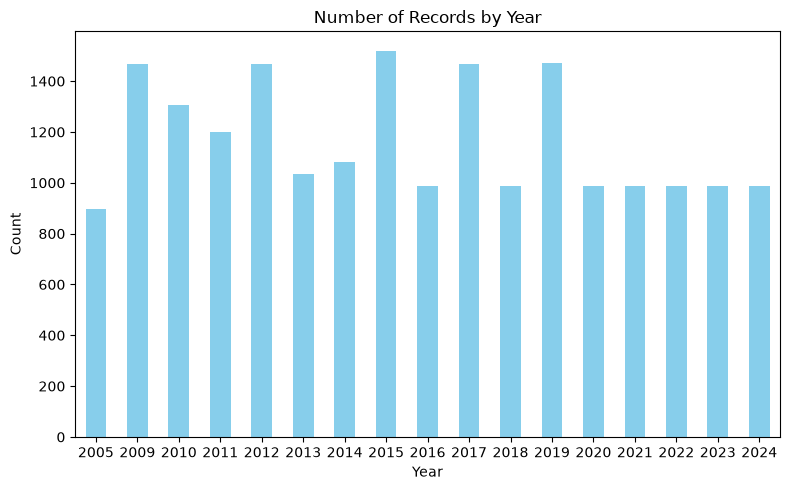

In [9]:


df['Start_Date'] = pd.to_datetime(df['Start_Date'])

# Count records by year
year_counts = df['Start_Date'].dt.year.value_counts().sort_index()

# Plot
plt.figure(figsize=(8, 5))
year_counts.plot(kind='bar', color='skyblue')

plt.title('Number of Records by Year')
plt.xlabel('Year')
plt.ylabel('Count')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

